## Libraries

In [10]:
from utils.data_loader import load_cifar10
from utils.plots import plot_sample_images, plot_training_history
from utils.models import build_lenet5_cifar10
import tensorflow as tf

## Loading MNIST dataset

In [3]:
(X_train_lenet5_cifar10, y_train_lenet5_cifar10), (X_test_lenet5_cifar10, y_test_lenet5_cifar10) = load_cifar10(flatten=False)
print(f"X_train: {X_train_lenet5_cifar10.shape}, y_train: {y_train_lenet5_cifar10.shape}")
print(f"X_test: {X_test_lenet5_cifar10.shape}, y_test: {y_test_lenet5_cifar10.shape}")

X_train: (50000, 32, 32, 3), y_train: (50000, 10)
X_test: (10000, 32, 32, 3), y_test: (10000, 10)


## Show MNIST dataset images 

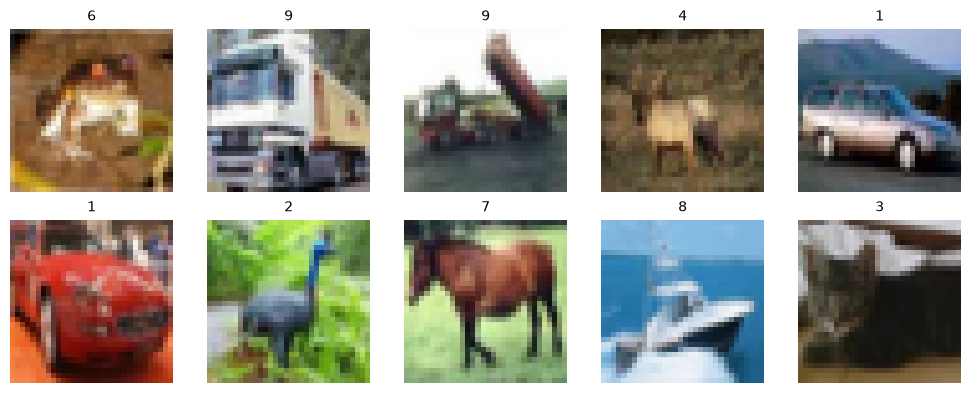

In [4]:
plot_sample_images(X_train_lenet5_cifar10[:10], y_train_lenet5_cifar10[:10])


## Model implementation and training

In [9]:
lenet_cifar10 = build_lenet5_cifar10(learning_rate=0.001, use_dropout=True)
lenet_cifar10.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 84)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,006 (242.21 KB)

 Trainable params: 62,006 (242.21 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2)
]

# 4. Entraînement
history_lenet_cifar = lenet_cifar10.fit(
    X_train_lenet5_cifar10,
    y_train_lenet5_cifar10,
    validation_data=(X_test_lenet5_cifar10, y_test_lenet5_cifar10),
    epochs=25,
    batch_size=64,
    callbacks=callbacks
)

Epoch 1/25
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.3552 - loss: 1.7442 - val_accuracy: 0.4361 - val_loss: 1.5461 - learning_rate: 0.0010
Epoch 2/25
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.4680 - loss: 1.4573 - val_accuracy: 0.5053 - val_loss: 1.3519 - learning_rate: 0.0010
Epoch 3/25
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.5121 - loss: 1.3548 - val_accuracy: 0.5275 - val_loss: 1.3036 - learning_rate: 0.0010
Epoch 4/25
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.5389 - loss: 1.2796 - val_accuracy: 0.5584 - val_loss: 1.2252 - learning_rate: 0.0010
Epoch 5/25
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.5590 - loss: 1.2349 - val_accuracy: 0.5691 - val_loss: 1.2070 - learning_rate: 0.0010
Epoch 6/25
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.5760 - loss: 1.1884 - val_accuracy: 0.5958 - val_loss: 1.1387 - learning_rate: 0.0010
Epoch 7/25
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.5918 - l

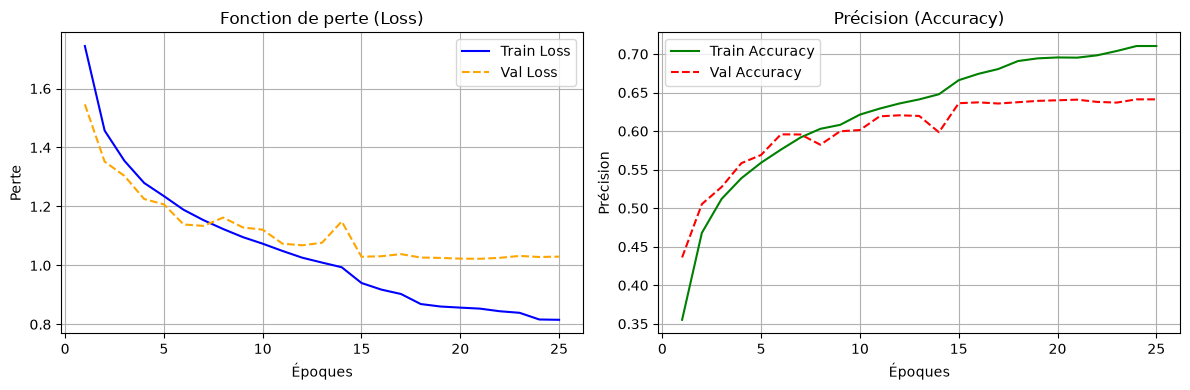

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6408 - loss: 1.0223
Précision LeNet-5 sur CIFAR-10 : 64.08%


In [12]:
plot_training_history(history_lenet_cifar)

test_loss, test_acc = lenet_cifar10.evaluate(X_test_lenet5_cifar10, y_test_lenet5_cifar10)
print(f"Précision LeNet-5 sur CIFAR-10 : {test_acc * 100:.2f}%")

In [13]:
lenet_cifar10.save("cnn_cifar.keras")